Project objectives
1. Load a real-world dataset.
2. Explore and understand the data.
3. Identify features and target.
4. Handle missing values.
5. Split the data correctly.
6. Build preprocessing pipelines.
7. Train multiple regression models.
8. Evaluate and compare models.
9. Tune hyperparameters.
10. Save the best model.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    KFold
)

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [3]:
housing = fetch_california_housing(as_frame=True)

df = housing.frame.copy()

df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [4]:
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nStatistical summary:")
display(df.describe())

Shape: (20640, 9)

Columns:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']

Data types:
MedInc         float64
HouseAge       float64
AveRooms       float64
AveBedrms      float64
Population     float64
AveOccup       float64
Latitude       float64
Longitude      float64
MedHouseVal    float64
dtype: object

Missing values:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Statistical summary:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


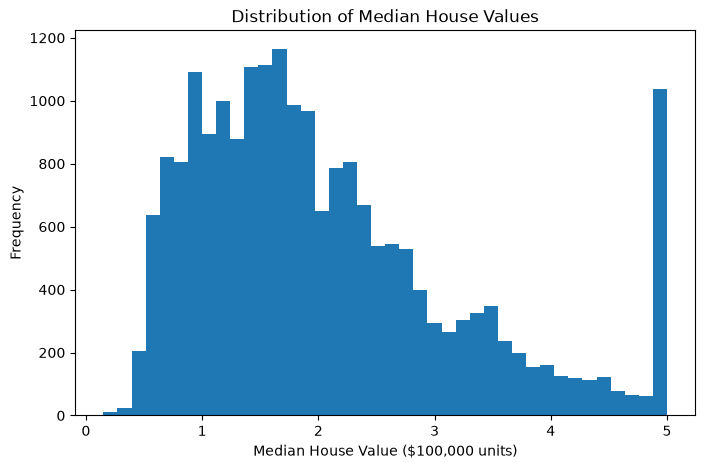

In [5]:
plt.figure(figsize=(8, 5))

plt.hist(df["MedHouseVal"], bins=40)

plt.xlabel("Median House Value ($100,000 units)")
plt.ylabel("Frequency")
plt.title("Distribution of Median House Values")

plt.show()

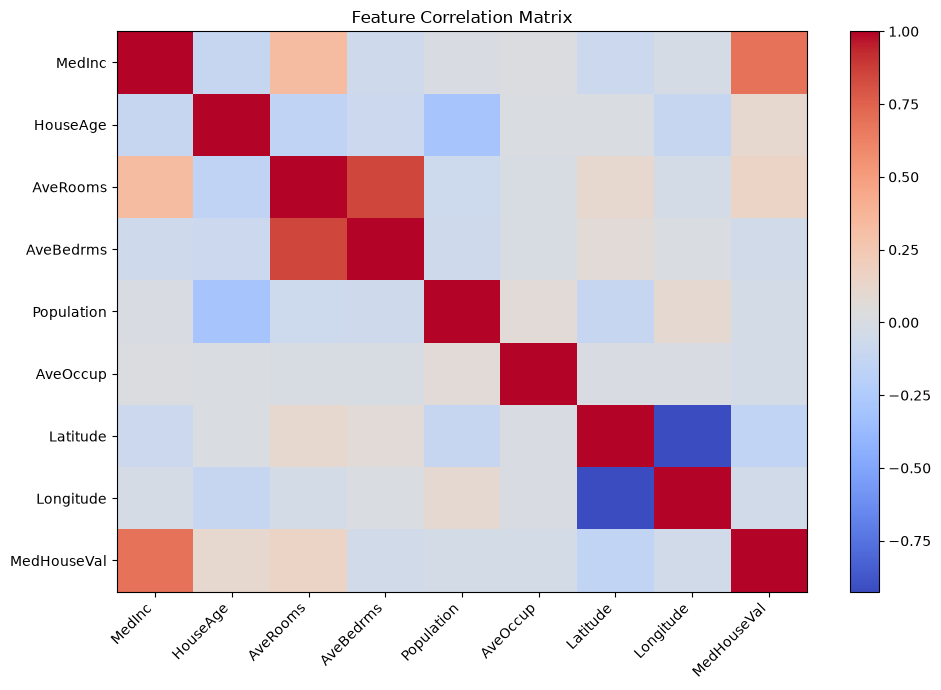

In [6]:
correlation = df.corr(numeric_only=True)

plt.figure(figsize=(10, 7))

plt.imshow(correlation, cmap="coolwarm", aspect="auto")
plt.colorbar()

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

In [7]:
X = df.drop(columns="MedHouseVal")
y = df["MedHouseVal"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (20640, 8)
Target: (20640,)


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (16512, 8)
Testing: (4128, 8)


In [9]:
linear_pipeline = Pipeline([
    ("imputer",SimpleImputer(strategy="median")),
    ("scaler",StandardScaler()),
    ("model",LinearRegression())
])

ridge_pipeline = Pipeline([
    ("imputer",SimpleImputer(strategy="median")),
    ("scaler",StandardScaler()),
    ("model",Ridge(alpha=1.0))
])

rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model",RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        random_state=42,
        n_jobs=-1
    ))
])

In [10]:
from sklearn.model_selection import cross_val_score

models = {
    "Linear Regression": linear_pipeline,
    "Ridge Regression": ridge_pipeline,
    "Random Forest": rf_pipeline
}

cv = KFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

results = []

for name, model in models.items():

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_mean_squared_error",
        n_jobs=-1
    )

    rmse_scores = np.sqrt(-scores)

    results.append({
        "Model": name,
        "Mean_CV_RMSE": rmse_scores.mean(),
        "Std_CV_RMSE": rmse_scores.std()
    })

results_df = pd.DataFrame(results)

display(results_df.sort_values("Mean_CV_RMSE"))

,Model,Mean_CV_RMSE,Std_CV_RMSE
2,Random Forest,0.518435,0.005417
1,Ridge Regression,0.720875,0.008061
0,Linear Regression,0.720877,0.008063


In [11]:
param_grid = {
    "model__alpha": [0.01, 0.1, 1, 10, 100]
}

grid_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print(
    "Best CV RMSE:",
    np.sqrt(-grid_search.best_score_)
)

Best parameters: {'model__alpha': 1}
Best CV RMSE: 0.7209205563377598


In [12]:
final_models = {
    **models,
    "Tuned Ridge": grid_search.best_estimator_
}

test_results = []

for name, model in final_models.items():

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    test_results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(
            mean_squared_error(y_test, predictions)
        ),
        "R2": r2_score(y_test, predictions)
    })

test_results_df = pd.DataFrame(test_results)

display(
    test_results_df.sort_values("RMSE")
)

,Model,MAE,RMSE,R2
2,Random Forest,0.333124,0.511366,0.800448
1,Ridge Regression,0.533193,0.745557,0.575816
3,Tuned Ridge,0.533193,0.745557,0.575816
0,Linear Regression,0.533200,0.745581,0.575788


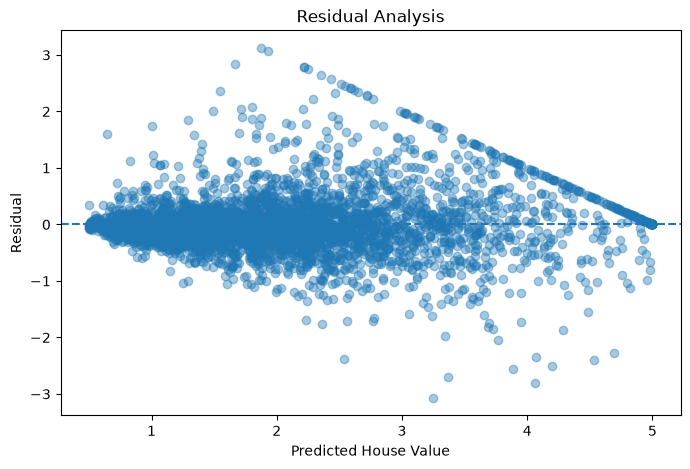

In [13]:
best_model = rf_pipeline

y_pred = best_model.predict(X_test)

residuals = y_test - y_pred

plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals, alpha=0.4)
plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted House Value")
plt.ylabel("Residual")
plt.title("Residual Analysis")

plt.show()

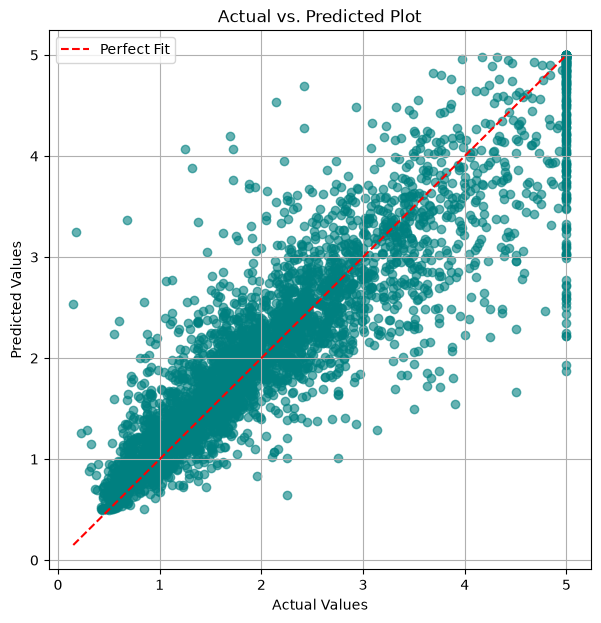

In [ ]:
plt.figure(figsize=(7, 7))
plt.scatter(y_test, y_pred, alpha=0.6, color="teal")

# Draw a perfect matching line down the middle
ideal_line = np.linspace(min(y_test), max(y_test), 100)
plt.plot(ideal_line, ideal_line, color="red", linestyle="--", label="Perfect Fit")

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs. Predicted Plot")
plt.legend()
plt.grid(True)
plt.show()

In [16]:
coefficients = (
    best_model.named_steps["model"].feature_importances_
)

coefficient_df = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": coefficients
})

display(
    coefficient_df.reindex(
        coefficient_df["Coefficient"].abs()
        .sort_values(ascending=False).index
    )
)

,Feature,Coefficient
0,MedInc,0.536234
5,AveOccup,0.138790
6,Latitude,0.087787
7,Longitude,0.087204
1,HouseAge,0.053074
2,AveRooms,0.041903
4,Population,0.027888
3,AveBedrms,0.027119


In [17]:
from pathlib import Path
import joblib

model_dir = Path("models")
model_dir.mkdir(parents=True, exist_ok=True)

model_path = model_dir / "california_house_rf_v1.joblib"

joblib.dump(best_model, model_path)

print("Model saved at:", model_path)

Model saved at: models\california_house_rf_v1.joblib


In [18]:
loaded_model = joblib.load(model_path)

sample = X_test.iloc[[0]]

prediction = loaded_model.predict(sample)

print("Predicted value:", prediction[0])
print("Actual value:", y_test.iloc[0])

Predicted value: 0.5249425074113706
Actual value: 0.477
